# gem5 results: exploration

Runs of `gem5/asymm/run_tiles.py` (report section "gem5 Simulation").
`tiles/` is the main grid with a free generator, `gencost/` is the slow
generator sweep (counter PRNG-FIFO, padding and prefetcher on).

Modes: 0 = $B$ in memory, 1 = seeded PRNG-FIFO, 2 = counter PRNG-FIFO.
Matrices 192 x 128 x 512, $A$ and $C$ fp32, $B$ int8.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.width", 140)
EXP = Path("../../../gem5/asymm/exp")
FIG = Path("figures/gem5")
M, K, N = 192, 128, 512
MODE = {0: "B in memory", 1: "seeded FIFO", 2: "counter FIFO"}

d = pd.read_csv(EXP / "tiles" / "results.csv")
g = pd.read_csv(EXP / "gencost" / "results.csv")
d["setting"] = "pad" + d["pad"].astype(str) + " pf" + d["prefetch"].astype(str)
len(d), len(g)

(315, 350)

## 1. Sanity checks

In [2]:
# memory B and the counter FIFO compute the same C
key = ["tm", "tn", "pad", "prefetch"]
m0 = d[d["mode"] == 0].set_index(key)["checksum"]
m2 = d[d["mode"] == 2].set_index(key)["checksum"]
print("checksum mismatches, memory B vs counter FIFO:", (m0 != m2).sum())

# FIFO reads on the correct path = all of B, 8 bytes per read, once per row band
d["reads"] = (M // d["tm"]) * K * N // 8
fifo = d[d["mode"] > 0]
print("runs with fewer FIFO reads than needed:", (fifo["pops"] < fifo["reads"]).sum())
print("runs with extra (wrong-path) FIFO reads:", (fifo["pops"] > fifo["reads"]).sum(), "of", len(fifo))

checksum mismatches, memory B vs counter FIFO: 0
runs with fewer FIFO reads than needed: 0
runs with extra (wrong-path) FIFO reads: 136 of 210


## 2. Main grid: cycles per MAC and the best tiles

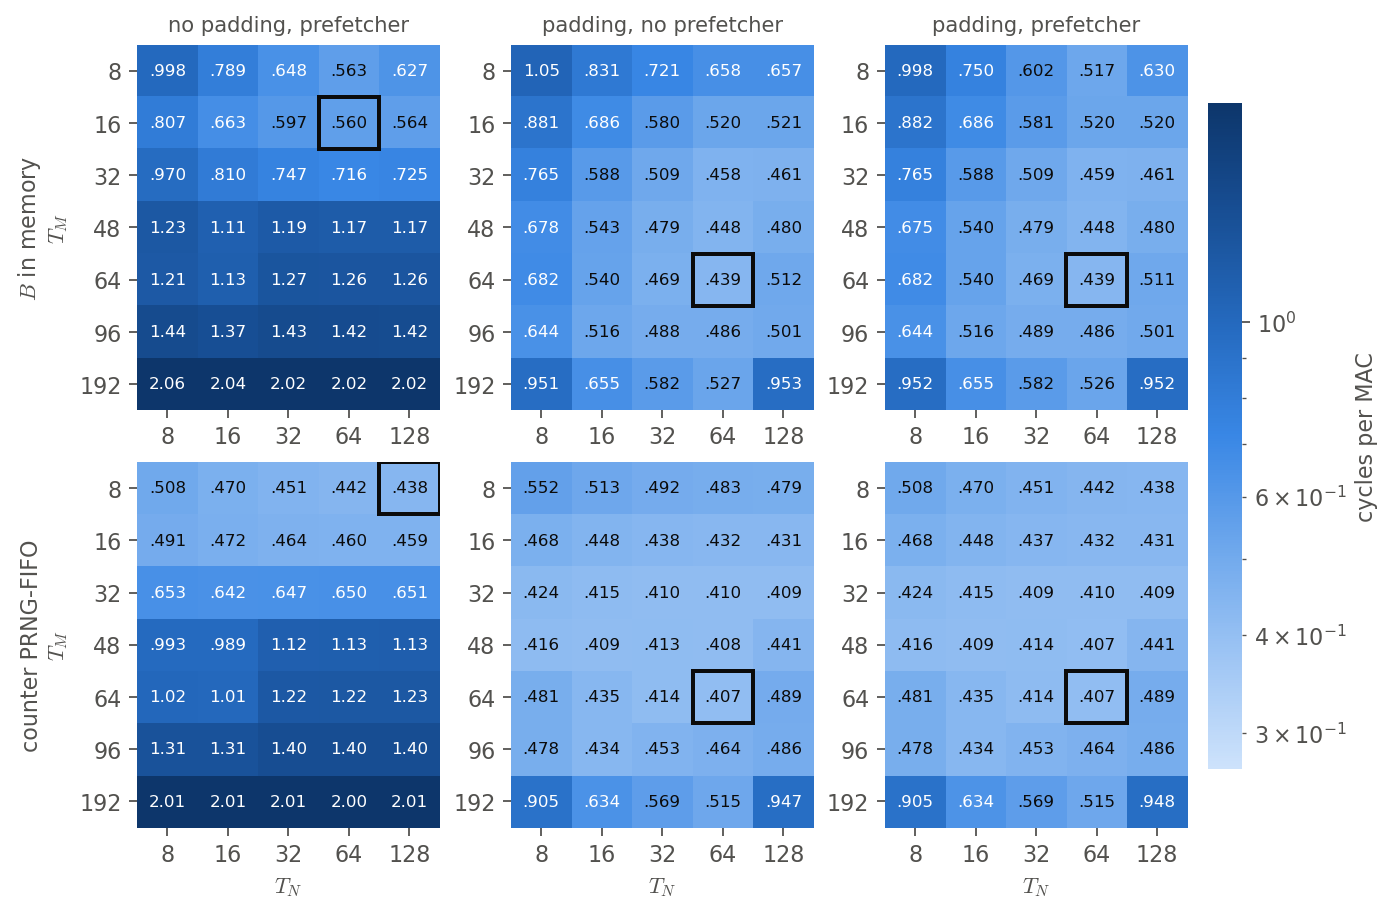

,mode,setting,tm,tn,cycles_per_mac
72,B in memory,pad0 pf1,16,64,0.560008
208,B in memory,pad16 pf0,64,64,0.439284
209,B in memory,pad16 pf1,64,64,0.438954
39,seeded FIFO,pad0 pf1,8,128,0.438365
211,seeded FIFO,pad16 pf0,64,64,0.407290
212,seeded FIFO,pad16 pf1,64,64,0.406939
42,counter FIFO,pad0 pf1,8,128,0.438390
214,counter FIFO,pad16 pf0,64,64,0.407296
215,counter FIFO,pad16 pf1,64,64,0.406945


In [3]:
display(Image(FIG / "gem5_cycles.png"))
best = (d.loc[d.groupby(["mode", "setting"])["cycles_per_mac"].idxmin(),
              ["mode", "setting", "tm", "tn", "cycles_per_mac"]]
        .assign(mode=lambda x: x["mode"].map(MODE)))
best

With padding the best tile is 64 x 64 for both sources of $B$, and the two
padding panels are almost the same: the prefetcher changes little (section 4
below). Without padding, $T_M \geq 32$ is ruined by set conflicts for both
sources of $B$ (section "Row padding" of the report: a column of $C$ maps to
2 of the 64 $L_1$ sets), and the best tiles become short ones.

In [4]:
def pivot(mode, setting, field="cycles_per_mac", data=d):
    s = data[(data["mode"] == mode) & (data["setting"] == setting)]
    return s.pivot(index="tm", columns="tn", values=field)

print("padding / no padding, B in memory, prefetcher on (<1: padding helps)")
display((pivot(0, "pad16 pf1") / pivot(0, "pad0 pf1")).round(2))
print("prefetcher on / off, with padding, counter FIFO (<1: prefetcher helps)")
display((pivot(2, "pad16 pf1") / pivot(2, "pad16 pf0")).round(3))

padding / no padding, B in memory, prefetcher on (<1: padding helps)


tn,8,16,32,64,128
tm,,,,,
8,1.00,0.95,0.93,0.92,1.00
16,1.09,1.03,0.97,0.93,0.92
32,0.79,0.73,0.68,0.64,0.64
48,0.55,0.49,0.40,0.38,0.41
64,0.56,0.48,0.37,0.35,0.41
96,0.45,0.38,0.34,0.34,0.35
192,0.46,0.32,0.29,0.26,0.47


prefetcher on / off, with padding, counter FIFO (<1: prefetcher helps)


tn,8,16,32,64,128
tm,,,,,
8,0.921,0.917,0.918,0.915,0.914
16,0.999,0.999,0.999,1.000,0.999
32,1.000,0.999,1.000,0.999,0.999
48,0.999,1.000,1.001,0.999,1.000
64,1.000,1.000,1.000,0.999,1.000
96,1.000,1.000,0.999,1.000,0.999
192,1.000,0.999,1.000,0.999,1.001


## 3. PRNG-FIFO against B in memory

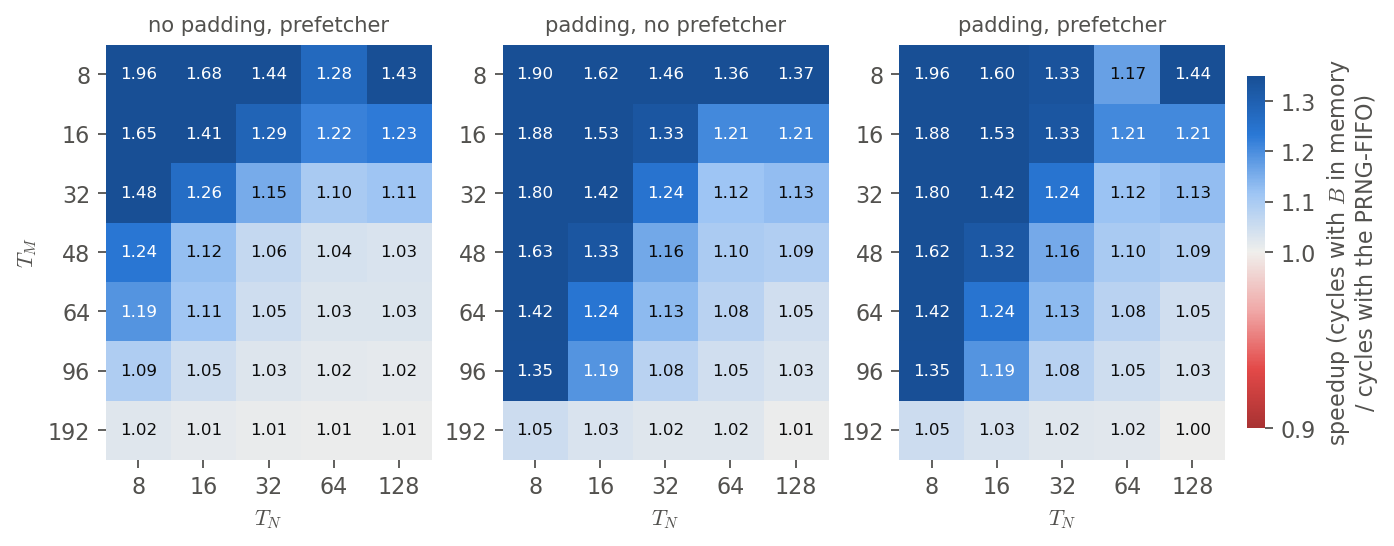

,setting,best_mem,best_fifo,best_vs_best,max_same_tile,min_same_tile,median_same_tile
0,pad0 pf1,0.560,0.438,1.277,1.964,1.007,1.112
1,pad16 pf0,0.439,0.407,1.079,1.901,1.006,1.205
2,pad16 pf1,0.439,0.407,1.079,1.963,1.004,1.189


In [5]:
display(Image(FIG / "gem5_speedup.png"))
rows = []
for s in sorted(d["setting"].unique()):
    b0 = pivot(0, s).min().min()
    b2 = pivot(2, s).min().min()
    sp = pivot(0, s) / pivot(2, s)
    rows.append(dict(setting=s, best_mem=b0, best_fifo=b2,
                     best_vs_best=b0 / b2, max_same_tile=sp.max().max(),
                     min_same_tile=sp.min().min(), median_same_tile=np.median(sp.values)))
pd.DataFrame(rows).round(3)

On the same tile the PRNG-FIFO gains most where $T_M$ is small, because
there $B$ is read again for every row band ($M / T_M$ times) and its traffic
is largest: up to 1.96x at 8 x 8. The best tile with $B$ in memory is already
tall (64 x 64), so best against best the gain is 8%. The FIFO never loses.

In [6]:
# bytes of B read per MAC with B in memory: every row band reads all of B once
for tm in [8, 16, 32, 64, 192]:
    print(f"T_M = {tm:3d}: {M // tm:2d} row bands, {1 / tm:.4f} bytes of B per MAC")

T_M =   8: 24 row bands, 0.1250 bytes of B per MAC
T_M =  16: 12 row bands, 0.0625 bytes of B per MAC
T_M =  32:  6 row bands, 0.0312 bytes of B per MAC
T_M =  64:  3 row bands, 0.0156 bytes of B per MAC
T_M = 192:  1 row bands, 0.0052 bytes of B per MAC


## 4. Capacity steps in the misses, and the prefetcher

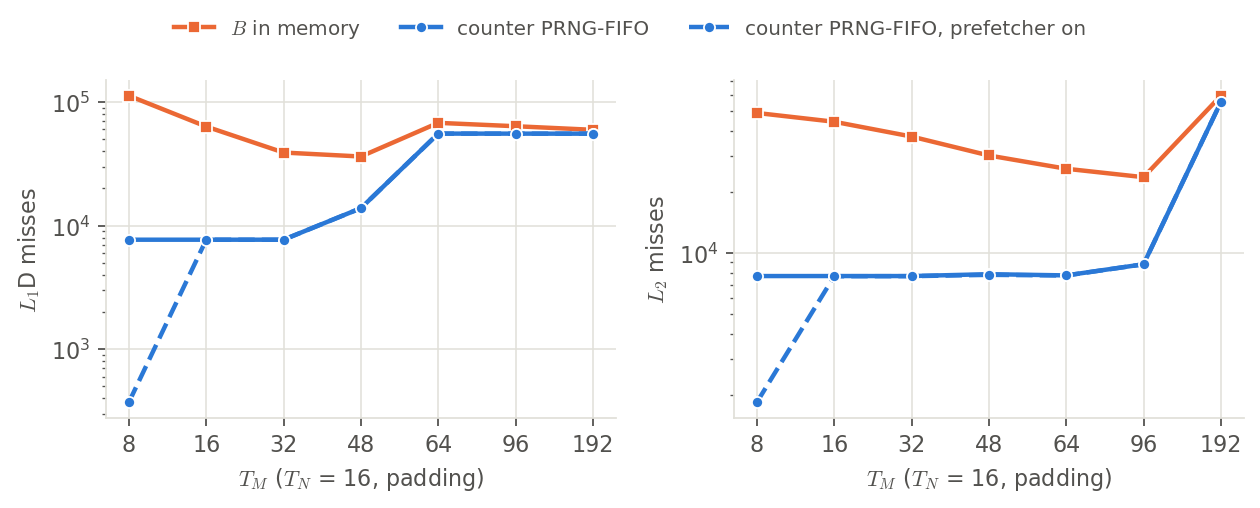

prefetcher 0


l1d_miss               l2_miss              
mode        0      1      2       0      1      2
tm                                               
8      112146   7686   7686   48901   7710   7711
16      63189   7686   7686   44265   7711   7712
32      38940   7686   7686   37443   7711   7711
48      36168  13822  13822   30212   7876   7876
64      67686  55398  55398   25998   7768   7769
96      63558  55366  55366   23631   8811   8813
192     59454  55329  55328   59445  55331  55333

prefetcher 1


l1d_miss               l2_miss              
mode        0      1      2       0      1      2
tm                                               
8       71297    373    373   67377   1858   1847
16      63186   7683   7683   44252   7696   7697
32      38937   7683   7683   37436   7701   7701
48      35891  13819  13819   30367   7817   7817
64      67685  55395  55395   25996   7759   7760
96      63557  55363  55363   23631   8806   8808
192     59453  55327  55327   59446  55335  55337

A strip (KB) per T_M: {8: 4, 16: 8, 32: 16, 48: 24, 64: 32, 96: 48, 192: 96}


In [7]:
display(Image(FIG / "gem5_misses.png"))
s = d[(d["tn"] == 16) & (d["pad"] == 16)]
for pf in (0, 1):
    t = s[s["prefetch"] == pf]
    print("prefetcher", pf)
    display(t.pivot(index="tm", columns="mode", values=["l1d_miss", "l2_miss"]).astype(int))
print("A strip (KB) per T_M:", {tm: tm * K * 4 // 1024 for tm in [8, 16, 32, 48, 64, 96, 192]})

The steps are where the strip of $A$ ($T_M \times K$ fp32) outgrows a cache:
$L_1$ (32 KB) between $T_M = 48$ (24 KB) and 64 (32 KB, together with the
tile of $C$ it no longer fits), $L_2$ (64 KB) at $T_M = 192$ (96 KB). With
$B$ in memory the $L_1$ misses first fall with $T_M$, because $B$ is read
$M / T_M$ times, then climb the same step.

The prefetcher only works at $T_M = 8$. There every load instruction steps
through memory with one fixed stride (32 bytes along $A$, 32 bytes along
$C$). In a taller tile each load instruction steps by a whole row block,
8 rows of $A$ (4.6 KB with padding) or of $C$ (16.9 KB), which is past the
end of the 4 KB page, and gem5's stride prefetcher does not prefetch across
pages. The stats below show it: identified candidates, zero issued.

In [8]:
def stat(run, name):
    for line in open(EXP / "tiles" / run / "stats.txt"):
        if line.startswith("---------- End"):
            break
        f = line.split()
        if len(f) > 1 and f[0] == name:
            return float(f[1])
    return None

rows = []
for tm in [8, 16, 64]:
    run = f"tm{tm}_tn16_m2_g0_c2048_p1_pad16_pop1"
    rows.append(dict(tm=tm,
                     l1_identified=stat(run, "system.cpu.dcache.prefetcher.pfIdentified"),
                     l1_issued=stat(run, "system.cpu.dcache.prefetcher.pfIssued"),
                     l1_useful=stat(run, "system.cpu.dcache.prefetcher.pfUseful"),
                     l1_misses=stat(run, "system.cpu.dcache.overallMisses::total")))
pd.DataFrame(rows)

,tm,l1_identified,l1_issued,l1_useful,l1_misses
0,8,30592.0,30586.0,7313.0,373.0
1,16,0.0,0.0,3.0,7683.0
2,64,221056.0,0.0,3.0,55395.0


## 5. Branch mispredictions and wrong-path reads

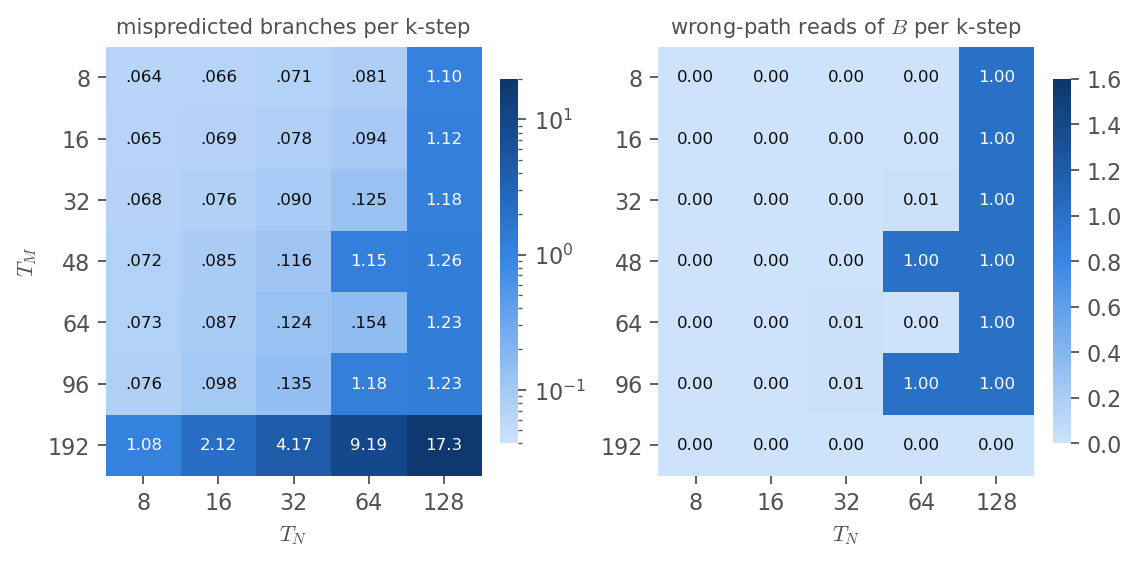

tn,8,16,32,64,128
tm,,,,,
8,0.06,0.07,0.07,0.08,1.10
16,0.07,0.07,0.08,0.09,1.12
32,0.07,0.08,0.09,0.12,1.18
48,0.07,0.08,0.12,1.15,1.26
64,0.07,0.09,0.12,0.15,1.23
96,0.08,0.10,0.13,1.18,1.23
192,1.08,2.12,4.17,9.19,17.34


In [9]:
display(Image(FIG / "gem5_mispredict.png"))
c = d[(d["mode"] == 2) & (d["setting"] == "pad16 pf1")].copy()
c["ksteps"] = (M // c["tm"]) * (N // c["tn"]) * (K // 8)
c["bp_per_kstep"] = c["cond_incorrect"] / c["ksteps"]
c.pivot(index="tm", columns="tn", values="bp_per_kstep").round(2)

The loops are predictable; what is mispredicted is loop exits. gem5's
tournament predictor keeps 11 bits of history, enough for a loop of up to 12
iterations:

- The loop over the row blocks of a tile has $T_M / 8$ iterations. At
  $T_M = 192$ that is 24, so its exit is mispredicted at every column block:
  $T_N / 8$ mispredictions per k-step (1.1, 2.1, 4.2, 9.2, 17.3). For
  $T_M \leq 96$ (12 row blocks or fewer) it is predicted.
- The loop over the column blocks has $T_N / 8$ iterations. At $T_N = 128$
  (16) its exit is mispredicted once per k-step. At $T_N = 64$ (8) it
  depends on the inner loop, which shares the global history: mispredicted
  at $T_M = 48$ and 96, predicted otherwise.
- Everywhere else there are under 0.15 mispredictions per k-step.

Only the second kind sends a read to the FIFO: after the last column block
the core starts a column block that does not exist, and its first load of
$B$ reaches the FIFO before the branch resolves. A mispredicted row-loop
exit starts another row block, which loads $A$ and $C$, not $B$. Hence the
right panel: one wrong-path read per k-step exactly where the column-block
exit is mispredicted, zero at $T_M = 192$ despite its many mispredictions.

Is the misprediction count the same for all sources of $B$?

In [10]:
p = d.pivot_table(index=["tm", "tn", "setting"], columns="mode", values="cond_incorrect")
(p.max(axis=1) - p.min(axis=1)).describe()

count    105.000000
mean       7.552381
std        5.930659
min        3.000000
25%        4.000000
50%        5.000000
75%        9.000000
max       30.000000
dtype: float64

For the counter PRNG-FIFO a wrong-path read only wastes generation time (it
pops 8 elements the core throws away). For the seeded PRNG-FIFO it moves the
stream on by 8 elements, so every later read of the tile gets the wrong
elements of $B$, until the next seed. One wrong-path read per k-step after
the first k-step leaves 15 of 16 k-steps wrong, 94%:

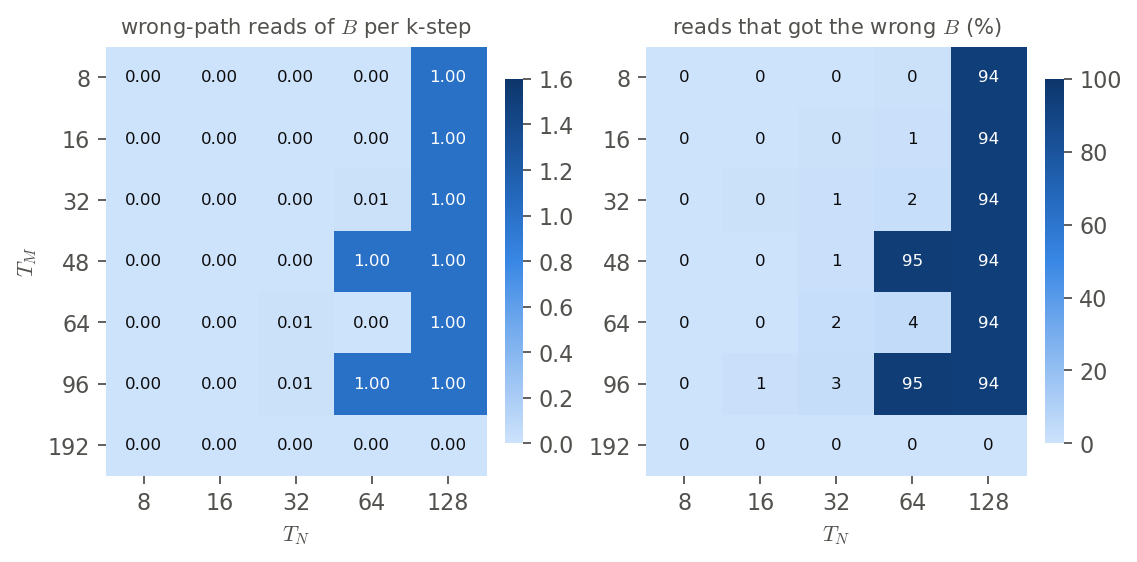

,tm,tn,pops,reads,stream_mismatch,wrong_pct
14,8,16,196609.0,196608,240.0,0.1
23,8,32,196609.0,196608,480.0,0.2
32,8,64,196611.0,196608,962.0,0.5
41,8,128,198144.0,196608,185760.0,94.5
59,16,16,98305.0,98304,240.0,0.2
68,16,32,98305.0,98304,480.0,0.5
77,16,64,98309.0,98304,964.0,1.0
86,16,128,99072.0,98304,92880.0,94.5
104,32,16,49153.0,49152,240.0,0.5
113,32,32,49153.0,49152,480.0,1.0


In [11]:
display(Image(FIG / "gem5_seeded.png"))
s = d[(d["mode"] == 1) & (d["setting"] == "pad16 pf1")].copy()
s["wrong_pct"] = 100 * s["stream_mismatch"] / s["reads"]
s[s["pops"] > s["reads"]][["tm", "tn", "pops", "reads", "stream_mismatch", "wrong_pct"]].round(1)

Also, a stream FIFO needs the compiler's cooperation: the kernel's eight loads
of a block of $B$ must stay in order. gcc reordered them in a first version
of the kernel, and every read got the wrong element. The kernel now has a
barrier between the loads, in all modes, so all modes run the same code.

## 6. Slow generator ($g_c > 0$)

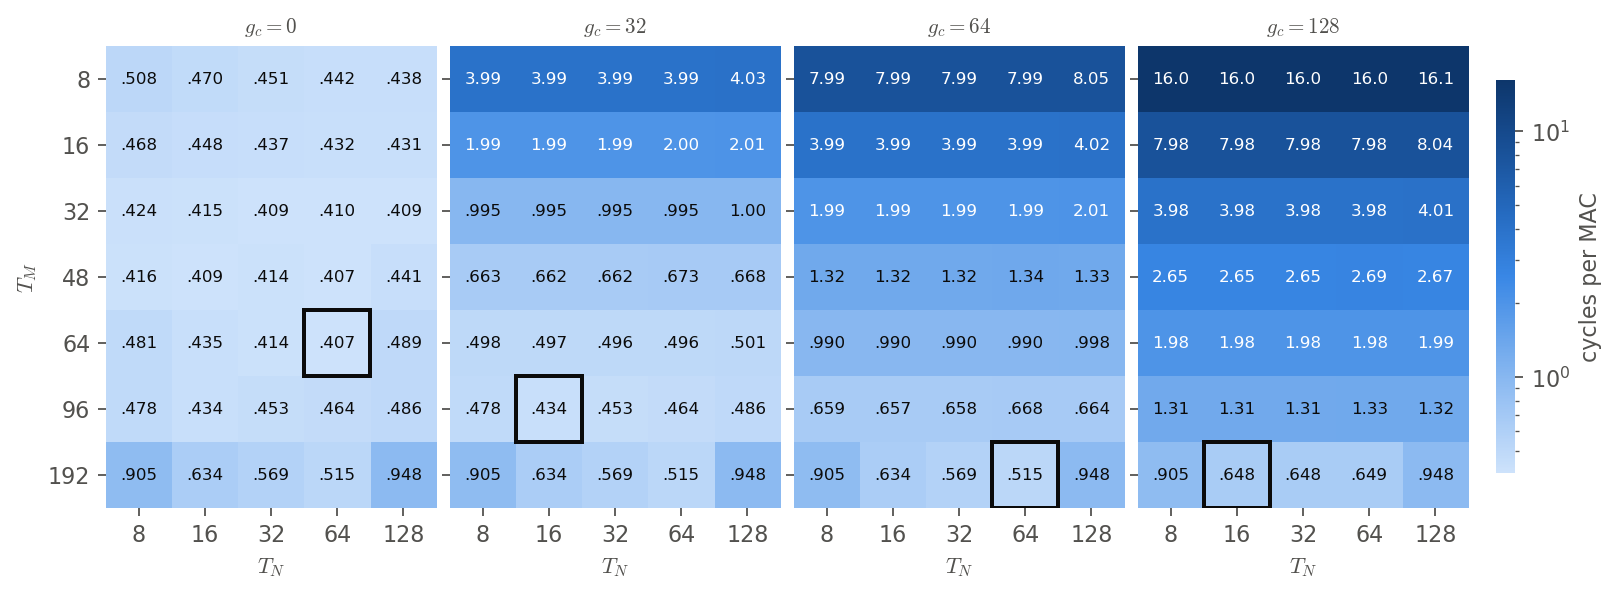

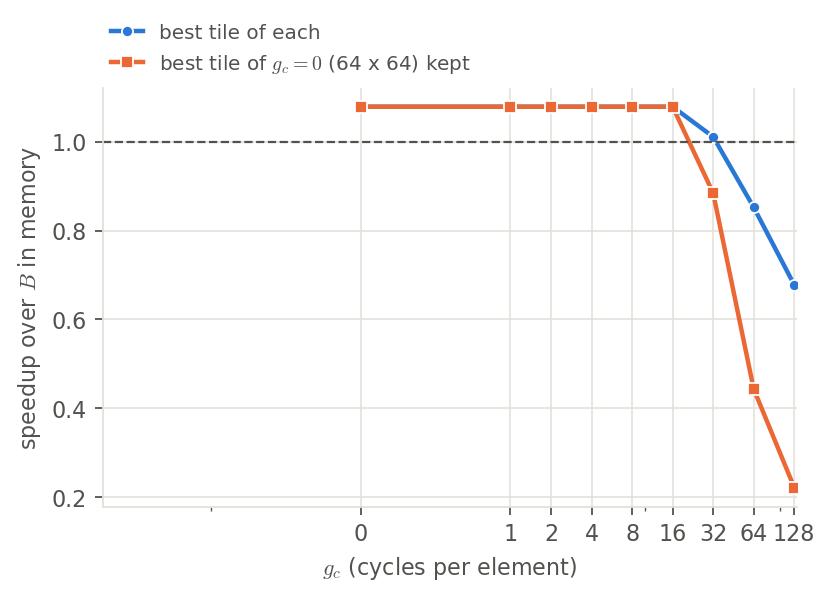

,gen_cost,tm,tn,cycles_per_mac,speedup_vs_mem_best,speedup_if_64x64_kept
231,0,64,64,0.407,1.079,1.079
232,1,64,64,0.407,1.079,1.079
233,2,64,64,0.407,1.079,1.079
234,4,64,64,0.407,1.079,1.079
235,8,64,64,0.407,1.079,1.079
236,16,64,64,0.407,1.079,1.079
267,32,96,16,0.434,1.011,0.884
338,64,192,64,0.515,0.852,0.443
319,128,192,16,0.648,0.678,0.222


In [12]:
display(Image(FIG / "gem5_gencost_tiles.png"))
display(Image(FIG / "gem5_gencost_speedup.png"))
f = g[g["mode"] == 2].copy()
mem_best = g[g["mode"] == 0]["cycles_per_mac"].min()
b = f.loc[f.groupby("gen_cost")["cycles_per_mac"].idxmin(), ["gen_cost", "tm", "tn", "cycles_per_mac"]]
b["speedup_vs_mem_best"] = mem_best / b["cycles_per_mac"]
kept = f[(f["tm"] == 64) & (f["tn"] == 64)].set_index("gen_cost")["cycles_per_mac"]
b["speedup_if_64x64_kept"] = mem_best / kept.loc[b["gen_cost"]].values
b.round(3)

Up to $g_c = 16$ nothing changes: $g_c / T_M$ is below the memory cost of
the 64 x 64 tile (0.41 cycles per MAC). From $g_c = 32$ the generation-bound
rows are exactly $g_c / T_M$ (1.0, 2.0, 4.0 at $T_M = 32, 16, 8$), and the
best tile moves up: 96 x 16, 192 x 64, 192 x 16. Against the best tile with
$B$ in memory the PRNG-FIFO breaks even at about $g_c = 32$ (1.01x). Keeping
the 64 x 64 tile instead of re-choosing costs up to 3x at $g_c = 128$.

### Does the report's model hold in gem5?

The model (section "Refining The Model") says the runtime of a tile is the
larger of its memory cost $\alpha$, measured once with a free generator, and
its generation cost $g_c / T_M$ per MAC. Check it against every gem5 run:

In [13]:
alpha = f[f["gen_cost"] == 0].set_index(["tm", "tn"])["cycles_per_mac"]
f["alpha"] = [alpha[(a, b_)] for a, b_ in zip(f["tm"], f["tn"])]
f["model"] = np.maximum(f["alpha"], f["gen_cost"] / f["tm"])
f["err_pct"] = 100 * (f["cycles_per_mac"] / f["model"] - 1)
print(f.groupby("gen_cost")["err_pct"].agg(["mean", "min", "max"]).round(1))

rows = []
for gc, t in f.groupby("gen_cost"):
    pick = t.loc[t["model"].idxmin()]
    best_ = t.loc[t["cycles_per_mac"].idxmin()]
    rows.append(dict(gen_cost=gc, model_tile=(int(pick.tm), int(pick.tn)),
                     best_tile=(int(best_.tm), int(best_.tn)),
                     loss_pct=100 * (pick.cycles_per_mac / best_.cycles_per_mac - 1)))
pd.DataFrame(rows).round(2)

          mean  min  max
gen_cost                
0          0.0  0.0  0.0
1          0.0  0.0  0.0
2          0.0  0.0  0.0
4          0.0 -0.1  0.7
8          0.0 -0.2  0.7
16        -0.0 -0.4  0.7
32        -0.1 -0.8  0.9
64        -0.3 -1.4  0.8
128       -0.6 -2.9  0.8


,gen_cost,model_tile,best_tile,loss_pct
0,0,"(64, 64)","(64, 64)",0.0
1,1,"(64, 64)","(64, 64)",0.0
2,2,"(64, 64)","(64, 64)",0.0
3,4,"(64, 64)","(64, 64)",0.0
4,8,"(64, 64)","(64, 64)",0.0
5,16,"(64, 64)","(64, 64)",0.0
6,32,"(96, 16)","(96, 16)",0.0
7,64,"(192, 64)","(192, 64)",0.0
8,128,"(192, 16)","(192, 16)",0.0


Within 3% everywhere, and the model's tile is gem5's best tile at every
$g_c$. gem5 is slightly faster than the model at large $g_c$ because the
counter FIFO starts full (2048 elements, a head start of $2048 g_c$
cycles), and because memory and generation overlap here better than in our
simulator: the generator is a separate unit and the core's reads just wait
for it.

## 7. gem5 against our simulator

# gem5 against our simulator

| $g_c$ | gem5 best | simulator best | loss in gem5 | rank correlation |
|---|---|---|---|---|
| 0 | 64 x 64 | 48 x 16 | 0.5% | 0.62 |
| 1 | 64 x 64 | 32 x 32 | 0.6% | 0.74 |
| 2 | 64 x 64 | 32 x 32 | 0.6% | 0.80 |
| 4 | 64 x 64 | 32 x 32 | 0.6% | 0.84 |
| 8 | 64 x 64 | 64 x 64 | 0.0% | 0.80 |
| 16 | 64 x 64 | 96 x 16 | 6.7% | 0.78 |
| 32 | 96 x 16 | 192 x 64 | 18.6% | 0.92 |
| 64 | 192 x 64 | 192 x 64 | 0.0% | 0.96 |
| 128 | 192 x 16 | 192 x 64 | 0.2% | 0.96 |



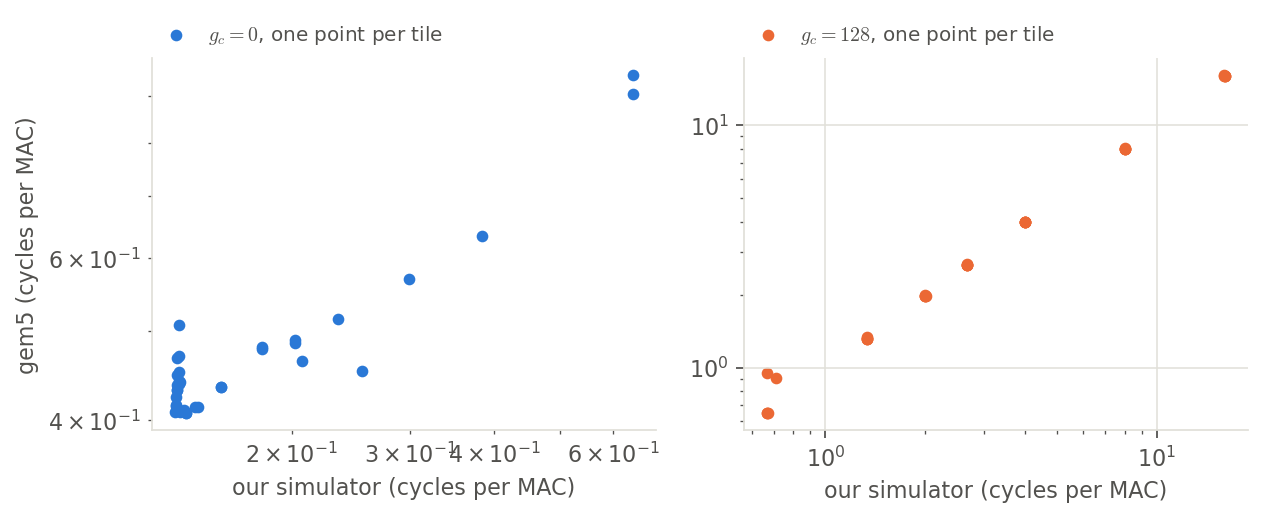

In [14]:
sim = Path("out/gem5_vs_sim/README.md")
print(sim.read_text() if sim.exists() else "run gem5_vs_sim.py first")
p = FIG / "gem5_vs_sim.png"
if p.exists():
    display(Image(p))

Our simulator (same matrices, caches, latencies and FIFO, fully associative
caches since the padded gem5 runs have no conflicts) ranks the 35 tiles like
gem5 with a rank correlation of 0.6 at $g_c = 0$ rising to 0.96 when
generation dominates. Its best tile costs under 1% in gem5 at most $g_c$;
the exceptions are $g_c = 16$ and 32, where memory and generation are about
equal and the two simulators place the crossover differently (7% and 19%).